Importing libraries:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Load Dataset:

In [2]:
dataset=pd.read_csv("holiday_dataset.csv")

Plot the Graph for Basic Understanding:

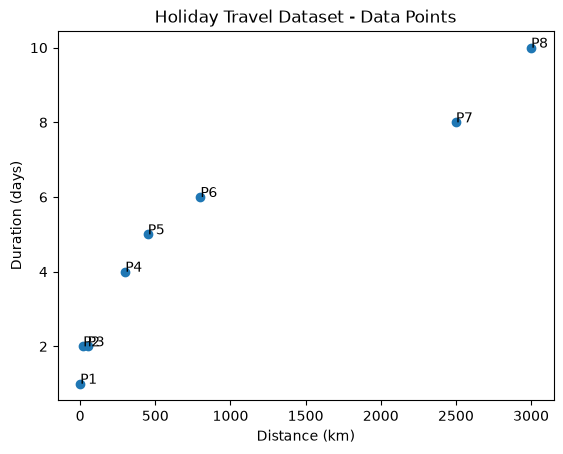

In [3]:
plt.scatter(dataset["Distance (km)"], dataset["Duration (days)"])

for idx in range(len(dataset)):
  plt.text(
      dataset["Distance (km)"].iloc[idx],
      dataset["Duration (days)"].iloc[idx],
      dataset["Person"].iloc[idx],
  )

plt.title("Holiday Travel Dataset - Data Points")
plt.xlabel("Distance (km)")
plt.ylabel("Duration (days)")
plt.show()

Features Split:

In [4]:
X=dataset.iloc[:,[1,2]].values

Find the Best clusters using Dendrogram:

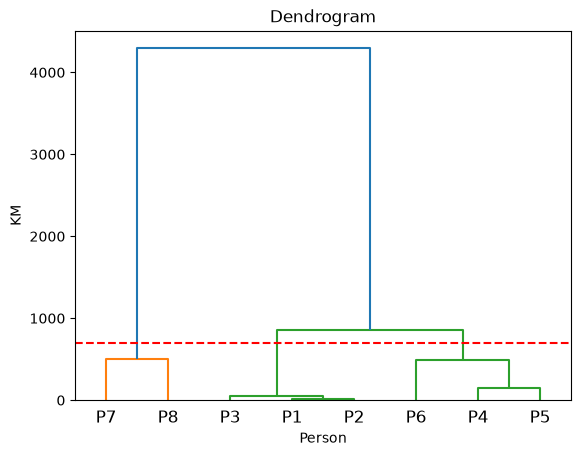

In [5]:
import scipy.cluster.hierarchy as sch
dendrogram=sch.dendrogram(sch.linkage(X,method='ward'),labels=dataset['Person'].values)
plt.axhline(y=700, color='r', linestyle='--')
plt.title("Dendrogram")
plt.xlabel("Person")
plt.ylabel("KM")
plt.show()

Standard Scaler:

In [6]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_scaled=sc.fit_transform(X)

Train a Model:

In [7]:
from sklearn.cluster import AgglomerativeClustering
cluster=AgglomerativeClustering(n_clusters=3)
labels=cluster.fit_predict(X_scaled)

Display the Cluster lables:

In [8]:
labels

array([2, 2, 2, 1, 1, 1, 0, 0])

Create a DataFrame to Existing Dataset:

In [9]:
clustered_Dataset=pd.DataFrame(dataset)

Add Labels to the Existing Dataset:

In [10]:
clustered_Dataset["Clustered_Group"]=labels
clustered_Dataset

,Person,Distance (km),Duration (days),Clustered_Group
0,P1,0,1,2
1,P2,20,2,2
2,P3,50,2,2
3,P4,300,4,1
4,P5,450,5,1
5,P6,800,6,1
6,P7,2500,8,0
7,P8,3000,10,0


Plot the Cluster's Graph:

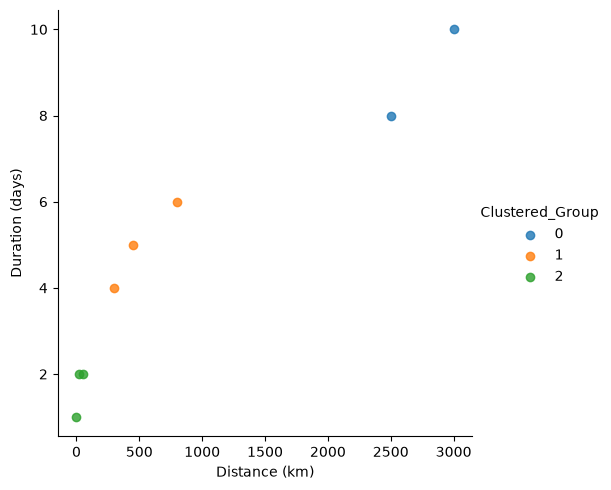

In [11]:
import seaborn as sns
facet=sns.lmplot(data=clustered_Dataset,x=clustered_Dataset.columns[1],y=clustered_Dataset.columns[2],hue=clustered_Dataset.columns[3],
                fit_reg=False,legend=True)
facet

Evaluation Metrics:

In [12]:
from sklearn.metrics import silhouette_score
score=silhouette_score(X_scaled,labels)
print("The Model Segregated score(-1 to +1) :",score)

The Model Segregated score(-1 to +1) : 0.6621522666595463


Average Distance (km) and Duration (days) by Cluster for Final Understanding:

In [13]:
clustered_final_group=clustered_Dataset.groupby('Clustered_Group')[
    ['Distance (km)','Duration (days)']
    ].mean()
print(clustered_final_group)

                 Distance (km)  Duration (days)
Clustered_Group                                
0                  2750.000000         9.000000
1                   516.666667         5.000000
2                    23.333333         1.666667


Count the Dataset Lables Based on Uniques:

In [14]:
print(clustered_Dataset['Clustered_Group'].value_counts())

Clustered_Group
2    3
1    3
0    2
Name: count, dtype: int64
